# 03 - Cost sensitivity

**SYNTHETIC DATA.** Each flat one-way cost REPLACES the detailed model (no double counting). Parameters and dates are fixed; the strategy is not re-tuned per cost level.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display
from backtester import experiments as ex
from backtester.config import make_run_factory
from backtester.performance import compute_metrics, metrics_frame
from backtester.strategies import build_strategy

ctx = ex.Context(Path.cwd())   # finds the project folder from notebooks/
ex.ensure_datasets(ctx.root)
print('project:', ctx.root.name, '| hold-out starts', ctx.holdout_start.date(), '(never used here)')

project: backtester | hold-out starts 2022-01-01 (never used here)


In [2]:
from backtester.config import deep_update
base = ctx.config('sma')
_, research, universe, mode = ctx.load(base)
rows = []
for bps in (0, 5, 10, 20, 50):
    cfg = deep_update({k: v for k, v in base.items() if k != 'costs'}, {'costs': {'proportional_bps': bps}})
    res = make_run_factory(cfg, universe, mode)(research, build_strategy('sma_crossover', **base['strategy']['params']), None)
    first = res.equity.index[res.equity['gross_exposure'] > 0][0]
    m = compute_metrics(res.returns(first), equity_frame=res.equity)
    rows.append({'bps': bps, 'cagr': m['cagr'], 'sharpe_rf0': m['sharpe'], 'max_dd': m['max_drawdown'],
                 'turnover': m['turnover_annual'], 'trading_costs': m['total_trading_costs']})
pd.DataFrame(rows)

,bps,cagr,sharpe_rf0,max_dd,turnover,trading_costs
0,0,0.036858,0.277768,0.531670,2.392424,0.000000
1,5,0.034395,0.266360,0.540954,2.392774,49183.924388
2,10,0.031933,0.254937,0.550060,2.393155,96066.271756
3,20,0.027007,0.232017,0.567842,2.393847,183279.065169
4,50,0.012367,0.163415,0.617060,2.395417,399069.866006


Saved table from `scripts/run_cost_sensitivity.py` (Sharpe there uses the 2% risk-free series, so it differs from the rf = 0 column above):

In [3]:
pd.read_csv(ctx.tables / 'cost_sensitivity.csv')

,strategy,one_way_bps,cagr,sharpe,max_drawdown,turnover_annual,total_trading_costs,net_financing,date_range
0,sma,0,0.036858,0.185193,0.531670,2.392424,0.000000,50266.027946,2005-10-10 to 2021-12-31
1,sma,5,0.034395,0.173812,0.540954,2.392774,49183.924388,48838.840700,2005-10-10 to 2021-12-31
2,sma,10,0.031933,0.162412,0.550060,2.393155,96066.271756,47476.358891,2005-10-10 to 2021-12-31
3,sma,20,0.027007,0.139549,0.567842,2.393847,183279.065169,44852.664311,2005-10-10 to 2021-12-31
4,sma,50,0.012367,0.071134,0.617060,2.395417,399069.866006,37994.052144,2005-10-10 to 2021-12-31
5,momentum,0,0.062637,0.299173,0.461952,4.136173,0.000000,5081.711657,2006-01-02 to 2021-12-31
6,momentum,5,0.058274,0.280231,0.467128,4.136904,94896.144165,4757.933948,2006-01-02 to 2021-12-31
7,momentum,10,0.053913,0.261233,0.472261,4.137608,182884.559487,4457.169110,2006-01-02 to 2021-12-31
8,momentum,20,0.045212,0.223144,0.482381,4.139088,339811.613476,3876.512490,2006-01-02 to 2021-12-31
9,momentum,50,0.019465,0.109129,0.531470,4.142872,687023.660804,2565.874937,2006-01-02 to 2021-12-31


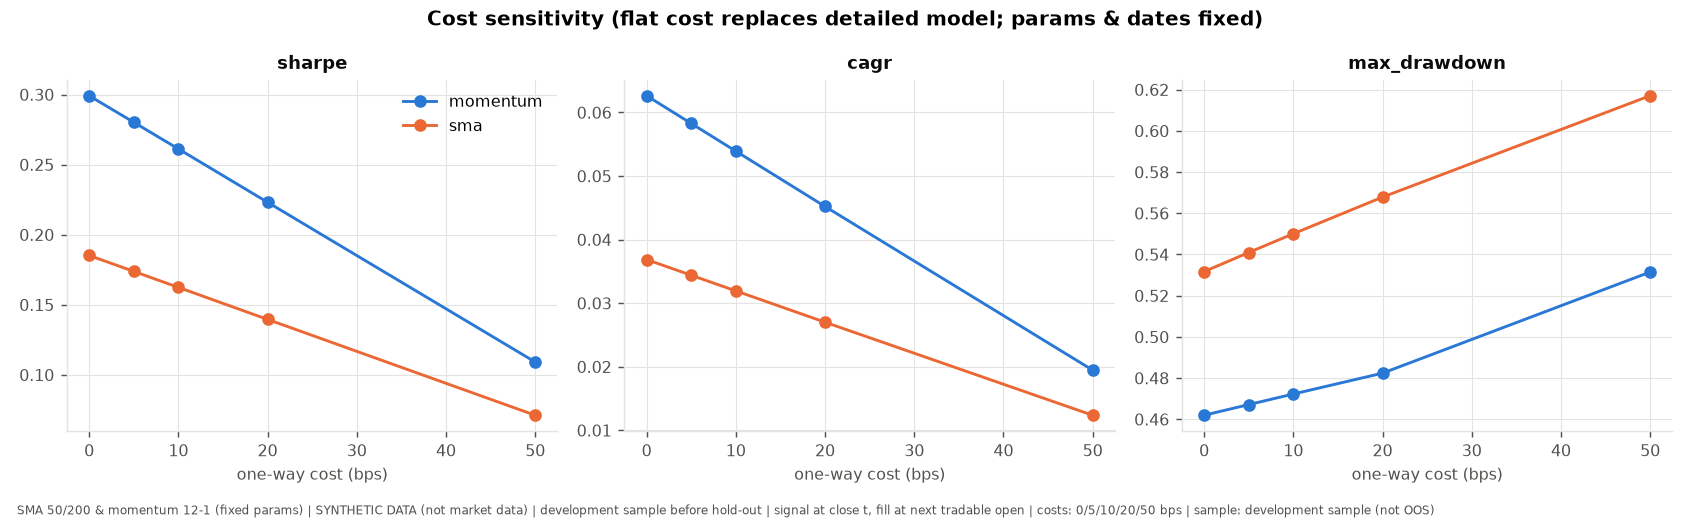

In [4]:
display(Image(filename=str(ctx.figs / '12_cost_sensitivity.png'), width=900))

In [5]:
pd.read_csv(ctx.tables / 'robustness_sma.csv')

,experiment,setting,cagr,sharpe,max_drawdown,ann_vol,avg_gross_exposure,turnover_annual,total_trading_costs
0,leverage_cap (fixed_fraction 0.5/asset),0.5,0.041886,0.240720,0.292111,0.120188,0.482454,1.478423,50287.471253
1,leverage_cap (fixed_fraction 0.5/asset),1.0,0.032822,0.166530,0.546164,0.208859,0.870243,2.393115,82184.796291
2,leverage_cap (fixed_fraction 0.5/asset),1.5,0.026424,0.162759,0.712047,0.276619,1.166926,2.719403,102799.652980
3,execution_delay_sessions,1,0.032822,0.166530,0.546164,0.208859,0.870243,2.393115,82184.796291
4,execution_delay_sessions,2,0.027934,0.143756,0.562745,0.208685,0.870437,2.268201,74309.934593
5,execution_delay_sessions,3,0.021631,0.114240,0.584160,0.208600,0.870156,2.203074,66213.606830
6,sizing_rule,equal_weight,0.032822,0.166530,0.546164,0.208859,0.870243,2.393115,82184.796291
7,sizing_rule,vol_target,0.039704,0.290512,0.176049,0.077969,0.340881,1.005258,28434.628934
8,sizing_rule,kelly,0.046316,0.333914,0.224254,0.089813,0.329065,0.921783,32533.021392
